# Cls 4. Sequence processing

## Data

In [1]:
with open("data/cls4/lisova_pisnia.txt", encoding="utf-8") as f:
    data = f.read()

print(len(data))
print(data[1000:1400])

85743
 - повна ніжної, задумливої поліської краси. Провесна. По узліссі і на галяві зеленіє перший ряст і цвітуть проліски та сон-трава. Дерева ще безлисті, але вкриті бростю, що от-от має розкритись. На озері туман то лежить пеленою, то хвилює од вітру, то розривається, одкриваючи блідо-блакитну воду.
В лісі щось загомоніло, струмок зашумував, забринів, і вкупі з його водами з лісу вибіг "Той, що гребл


## Tokenization

In [2]:
symbols = sorted(set(data))
s2i = {s: i for i, s in enumerate(symbols)}
i2s = {i: s for i, s in enumerate(symbols)}
encode = lambda text: [s2i[s] for s in text]
decode = lambda idx: "".join(i2s[i] for i in idx)

print("".join(symbols))
print(len(symbols))


 !"'(),-./0123456789:;?IV[]ЄІЇАБВГДЕЖЗИЙКЛМНОПРСТУХЦЧШЩЯабвгдежзийклмнопрстуфхцчшщьюяєії№
90


In [3]:
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

data_idx = torch.tensor(encode(data))
n = int(0.9 * len(data_idx))
train_idx, val_idx = data_idx[:n], data_idx[n:]
device

'mps'

## Embeddings

In [4]:
h_hidden = 64
emb = nn.Embedding(len(symbols), h_hidden)

x = data_idx[:10]
x_emb = emb(x)
x_emb.shape

torch.Size([10, 64])

## Attention

Single head with a causal mask: position `t` can only look at positions `<= t`.

torch.Size([10, 64])

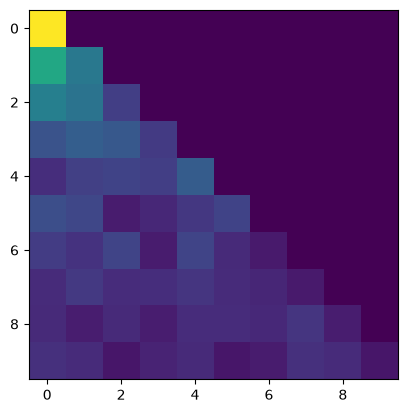

In [5]:
import math
import matplotlib.pyplot as plt

q_proj, k_proj, v_proj = (nn.Linear(h_hidden, h_hidden) for _ in range(3))
q, k, v = q_proj(x_emb), k_proj(x_emb), v_proj(x_emb)

T = len(x)
attn = q @ k.T / math.sqrt(h_hidden)
attn = attn.masked_fill(torch.tril(torch.ones(T, T)) == 0, float("-inf"))
attn = torch.softmax(attn, dim=-1)
out = attn @ v

plt.imshow(attn.detach())
out.shape

## Transformer model

In [ ]:
from dataclasses import dataclass

@dataclass
class Config:
    vocab_size: int = len(symbols)
    block_size: int = 128
    n_layer: int = 4
    n_head: int = 4
    n_embd: int = 128
    dropout: float = 0.1


class CausalSelfAttention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.n_head = c.n_head
        self.qkv = nn.Linear(c.n_embd, 3 * c.n_embd)
        self.proj = nn.Linear(c.n_embd, c.n_embd)
        self.drop = nn.Dropout(c.dropout)
        self.register_buffer("mask", torch.tril(torch.ones(c.block_size, c.block_size)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, n_head, T, head_size)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        att = q @ k.transpose(-2, -1) / math.sqrt(k.size(-1))
        att = att.masked_fill(self.mask[:T, :T] == 0, float("-inf"))
        att = self.drop(F.softmax(att, dim=-1))
        y = (att @ v).transpose(1, 2).reshape(B, T, C)  # concatenate heads
        return self.drop(self.proj(y))


class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(c.n_embd), nn.LayerNorm(c.n_embd)
        self.attn = CausalSelfAttention(c)
        self.mlp = nn.Sequential(
            nn.Linear(c.n_embd, 4 * c.n_embd), nn.GELU(),
            nn.Linear(4 * c.n_embd, c.n_embd), nn.Dropout(c.dropout),
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


class GPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.tok_emb = nn.Embedding(c.vocab_size, c.n_embd)
        self.pos_emb = nn.Embedding(c.block_size, c.n_embd)
        self.blocks = nn.Sequential(*[Block(c) for _ in range(c.n_layer)])
        self.ln_f = nn.LayerNorm(c.n_embd)
        self.head = nn.Linear(c.n_embd, c.vocab_size)

    def forward(self, idx, targets=None):
        T = idx.size(1)
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        logits = self.head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.flatten(0, 1), targets.flatten())
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.c.block_size:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = -float("inf")
            idx_next = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [7]:
config = Config()
model = GPT(config).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

0.83M parameters


In [8]:
def sample(prompt, max_new_tokens=300, **kw):
    model.eval()
    idx = torch.tensor([encode(prompt)], device=device)
    return decode(model.generate(idx, max_new_tokens, **kw)[0].tolist())

print(sample("Мавка"))

Мавкафб0.V]шРнз2.жІ:'ГЦIю79ОПдоЧ:ВХ
чСвЗПРИ7,и4ятбХю(вЗге/юя5Б№4
Щ(:У;V0I1дIю9
ж к3Р
Й№ЗЄщМIуєччц3Бзи!Вр,-:г-Д6ДсЗнЧф!КіI)ЩИЄозмЙа3ОЛ№У0:Б.)МШ! Нн9ДОЕ0!буVО! 5чЦцц]ТД"лЇ8ЕдШХйИОГОХАЗУк'РЯтїЩрфчвХДлрМ!пР??пхЯЙткшЙI79!IНАнVкОй!ефе4/№НАЇ9 ;ХИуЦЕШі2Ї!ОЄЩ!4х/ЯХдЖ6.Б2Да!9ТуАеА!ЙиЙБе?в90НеЗ/О9''чбфГККмвяКоИЙР;I


## Training

In [9]:
batch_size = 32

def get_batch(split):
    d = train_idx if split == "train" else val_idx
    ix = torch.randint(len(d) - config.block_size - 1, (batch_size,))
    x = torch.stack([d[i : i + config.block_size] for i in ix])
    y = torch.stack([d[i + 1 : i + 1 + config.block_size] for i in ix])
    return x.to(device), y.to(device)

@torch.no_grad()
def estimate_loss(n_batches=20):
    model.eval()
    res = {s: torch.stack([model(*get_batch(s))[1] for _ in range(n_batches)]).mean().item()
           for s in ("train", "val")}
    model.train()
    return res

In [10]:
max_steps, eval_every = 1500, 100
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.1)
history = []

model.train()
for step in range(max_steps + 1):
    if step % eval_every == 0:
        losses = estimate_loss()
        history.append((step, losses["train"], losses["val"]))
        print(f"step {step:5d}  train {losses['train']:.3f}  val {losses['val']:.3f}")
    x, y = get_batch("train")
    _, loss = model(x, y)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step     0  train 4.719  val 4.711


step   100  train 2.656  val 2.671


step   200  train 2.557  val 2.596


step   300  train 2.381  val 2.427


step   400  train 2.233  val 2.302


step   500  train 2.130  val 2.220


... (6 outputs left out)

step  1200  train 1.612  val 1.948


step  1300  train 1.559  val 1.923


step  1400  train 1.504  val 1.915


step  1500  train 1.457  val 1.906


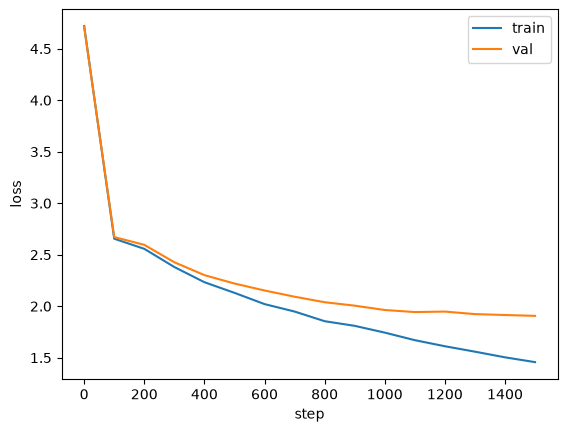

In [11]:
steps, tr, va = zip(*history)
plt.plot(steps, tr, label="train")
plt.plot(steps, va, label="val")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend();

## Inference with sampling

- `temperature < 1` sharpens the distribution (safer, more repetitive), `> 1` flattens it (more random).
- Speaker names in the play are letter-spaced (`М а в к а`), so prompts use the same format.
- `top_k` keeps only the `k` most likely next characters before sampling.

In [12]:
prompt = "М а в к а\n"
for t in (0.5, 0.8, 1.2):
    print(f"--- temperature={t} ---")
    print(sample(prompt, temperature=t, top_k=20))
    print()

--- temperature=0.5 ---


М а в к а
Як бачу не пробув розмаяла.
М а в к а
Ну, я не знаю.
Л у к а ш
Та ти б не вже знаю.
К и л и н а
(від неї)
А ти бачиш?
М а в к а
Відби не зався, не хочу думарі вкупи з нею.
Л у к а ш
Та знаю.
Л у к а ш
(сміхнувшись)
А ти не не так? Що ж то бути заснула.
М а в к а
Ні, то я б не знаю.
Л у к а ш
Та й, щ

--- temperature=0.8 ---


М а в к а
Я неможе заплати дубом кала.
Я ж добре верба твоя він подали у волита.

Лукаш поглядає до мені дуже сталого заглядить до лісу духу перед маленями.
М а в к а
А то ж добре по ливала,
та в лісі!
Л у к а ш
Віддай! Та бачу дас брегати.
Вона світро до мене круду придилі рудко може повіттям неба сопілко пу

--- temperature=1.2 ---


М а в к а
Ми, вдивли де мовні зогили,
де хто б з тако гнуджу.
Л е в
Цілуйно може!
Таке й я! Вже так знаю, я як
заввтрениче лата,
братавши покрися дубому повиці подрігодомі?
К у л к а
Баба!
Л у к а ш
Тих! не капчик, я їх маю, знайде тула.
М а в к а
Бяг далово таки може смаю.
Віно невихом пропівні нетемо надмір



In [13]:
print(sample("Л у к а ш\nО, як же ти ", max_new_tokens=500, temperature=0.8, top_k=10))

Л у к а ш
О, як же ти знайдутила
до той, щоб не постав собі поважні тепера,
що він побила по чим.
М а в к а
Він не рідні від серці по поластого не бачив знатися по з дерейне над.

М а в к а
Дай світі прихилась видкою драгою.

Л у к а ш
Ти ж не нас не хороже може... Я буду засно жаробок.
М а в к а
Се вже тогоді маю ж бувати!
М а в к а
Се тут маю
які звід вибуденьма на себе вас до прийдеться по равіті...
Він тебе засте, ще покра про по лісі все він простує по не світі пучинать полискадається до озеро, помуваючи до себе
